In [1]:
import random
import time

import numpy as np
import pandas as pd
import ptwt
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    auc,
    f1_score,
    precision_score,
    recall_score,
    roc_curve,
    confusion_matrix
)
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import DataLoader, Dataset

In [2]:
EPOCHS = 100
BATCH_SIZE = 32
SEED = 42
WAVELET_FAMILIES = ["db4", "db6", "db8", "db14", "db16", "db18", "db24", "db26", "db28", "db34", "db36", "db38"]

if torch.backends.mps.is_available():
    device = torch.device("mps")
    print("Success: Mac GPU (MPS) is available!")
else:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

random.seed(SEED)
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.backends.mps.is_available():
    torch.mps.manual_seed(SEED)

cuda


In [3]:
def load_split(name):
    X = np.load(f"../Data/{name}_features.npy", mmap_mode="r")
    meta = pd.read_csv(f"../Data/{name}_meta.csv")

    X = np.asarray(X, dtype=np.float32).reshape(X.shape[0], -1, X.shape[-1])
    y = meta["is_bonafide"].to_numpy().astype(np.int64)

    return X, y, meta

In [4]:
t0 = time.time()
X_train, y_train, train_meta = load_split("train")
X_dev, y_dev, dev_meta = load_split("dev")
X_eval, y_eval, eval_meta = load_split("eval")
print(f"{time.time() - t0:.1f}s | train {X_train.shape} | dev {X_dev.shape} | eval {X_eval.shape}")

3.6s | train (25380, 40, 401) | dev (24844, 40, 401) | eval (71237, 40, 401)


In [5]:
row_mean = X_train.mean(axis=(0, 2), keepdims=True)
row_std = X_train.std(axis=(0, 2), keepdims=True) + 1e-6

X_train = (X_train - row_mean) / row_std
X_dev = (X_dev - row_mean) / row_std
X_eval = (X_eval - row_mean) / row_std

In [6]:
class AudioFeaturesDataset(Dataset):

    def __init__(self, X, y):
        self.X = torch.from_numpy(X).unsqueeze(1)
        self.y = torch.from_numpy(y)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [7]:
train_dataset = AudioFeaturesDataset(X_train, y_train)
dev_dataset = AudioFeaturesDataset(X_dev, y_dev)
eval_dataset = AudioFeaturesDataset(X_eval, y_eval)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

dev_loader = DataLoader(
    dev_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

eval_loader = DataLoader(
    eval_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

In [8]:
def conv_block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(cout),
        nn.ReLU(inplace=True),
    )


class AverageCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            conv_block(1, 32),
            conv_block(32, 32),
            nn.MaxPool2d(kernel_size=2),

            conv_block(32, 64),
            conv_block(64, 64),
            nn.MaxPool2d(kernel_size=2),

            conv_block(64, 128),
            conv_block(128, 128),
            nn.MaxPool2d(kernel_size=2),

            conv_block(128, 256),
            conv_block(256, 256),
            nn.Dropout2d(0.1),
        )

        self.classifier = nn.Sequential(
            nn.Linear(512, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(128, 2),
        )

    def forward(self, x):
        x = self.features(x)
        x = x.mean(dim=2)
        x = torch.cat([x.mean(dim=2), x.std(dim=2)], dim=1)
        return self.classifier(x)

In [9]:
num_bonafide = int(y_train.sum())
num_spoof = int(len(y_train) - num_bonafide)

print(num_bonafide, num_spoof)

total = num_bonafide + num_spoof

weight_bonafide = total / (2 * num_bonafide)
weight_spoof = total / (2 * num_spoof)

class_weights = torch.tensor(
    [weight_spoof, weight_bonafide],
    dtype=torch.float32
).to(device)

2580 22800


In [10]:
class EarlyStopper:
    def __init__(self, patience=15, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best = float('inf')

    def early_stop(self, validation_metric):
        if validation_metric < self.best:
            self.best = validation_metric
            self.counter = 0
        else:
            self.counter += 1

        return self.counter >= self.patience

In [11]:
def calculate_eer(labels, scores):
    fpr, tpr, thresholds = roc_curve(labels, scores, pos_label=1)
    fnr = 1 - tpr
    diff = fpr - fnr
    i = int(np.argmax(diff >= 0))
    if i == 0 or diff[i] == diff[i - 1]:
        eer = (fpr[i] + fnr[i]) / 2
    else:
        t = -diff[i - 1] / (diff[i] - diff[i - 1])
        eer = fpr[i - 1] + t * (fpr[i] - fpr[i - 1])
    return float(eer), float(thresholds[i])


def llr_score(logits):
    return logits[:, 1] - logits[:, 0]

In [12]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    total = 0
    all_labels = []
    all_scores = []

    for X, y in loader:

        X = X.to(device)
        y = y.to(device)

        optimizer.zero_grad(set_to_none=True)

        logits = model(X)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * X.size(0)
        total += y.size(0)
        all_labels.append(y.detach().cpu())
        all_scores.append(llr_score(logits).detach().cpu())

    epoch_loss = running_loss / total
    epoch_eer, _ = calculate_eer(
        torch.cat(all_labels).numpy(),
        torch.cat(all_scores).numpy()
    )

    return epoch_loss, epoch_eer

In [13]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    total = 0

    all_labels = []
    all_scores = []

    for X, y in loader:
        X = X.to(device)
        y = y.to(device)

        logits = model(X)
        loss = criterion(logits, y)
        running_loss += loss.item() * X.size(0)
        total += y.size(0)

        all_labels.append(y.cpu())
        all_scores.append(llr_score(logits).cpu())

    all_labels = torch.cat(all_labels).numpy()
    all_scores = torch.cat(all_scores).numpy()

    epoch_loss = running_loss / total
    eer, threshold = calculate_eer(all_labels, all_scores)
    all_predictions = (all_scores >= threshold).astype(int)

    return (
        epoch_loss,
        eer,
        threshold,
        all_labels,
        all_predictions,
        all_scores,
    )

In [14]:
def run_model(model, criterion, optimizer, scheduler):
    history = {
        "train_loss": [],
        "train_eer": [],
        "dev_loss": [],
        "dev_eer": [],
        "lr": [],
    }

    best_dev_eer = float("inf")
    best_model_state = None
    best_model_status = {}

    early_stopper = EarlyStopper(patience=10)
    for epoch in range(EPOCHS):
        train_loss, train_eer = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            device
        )

        dev_loss, dev_eer, _, _, _, _ = evaluate(
            model,
            dev_loader,
            criterion,
            device
        )

        scheduler.step(dev_eer)

        history["train_loss"].append(train_loss)
        history["train_eer"].append(train_eer)

        history["dev_loss"].append(dev_loss)
        history["dev_eer"].append(dev_eer)
        history["lr"].append(optimizer.param_groups[0]['lr'])

        if dev_eer < best_dev_eer:
            best_dev_eer = dev_eer
            best_model_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            best_model_status = {
                "epoch": epoch+1,
                "train_loss": train_loss,
                "train_eer": train_eer,
                "dev_loss": dev_loss,
                "best_dev_eer": best_dev_eer
            }

        if early_stopper.early_stop(dev_eer):
            print("Early Stopping...")
            break

        print(
            f"Epoch {epoch + 1:02d}/{EPOCHS} | "
            f"LR: {history['lr'][-1]:.6f} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train EER: {train_eer:.6f} | "
            f"Dev Loss: {dev_loss:.4f} | "
            f"Dev EER: {dev_eer:.6f} | "
            f"ES Counter: {early_stopper.counter}/{early_stopper.patience}"
        )

    print(f"Best Model: {best_model_status}")

    return history, best_model_state

In [15]:
def setup_model():
    model = AverageCNN().to(device)

    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-4,
        weight_decay=1e-4
    )

    scheduler = ReduceLROnPlateau(
        optimizer,
        mode='min',
        factor=0.1,
        patience=5,
        threshold=1e-4,
        min_lr=1e-6
    )

    history, best_model_state = run_model(model, criterion, optimizer, scheduler)
    return model, criterion, history, best_model_state

In [ ]:
results = []
model, criterion, history, best_model_state = setup_model()

model.load_state_dict(best_model_state)
model.to(device)
model.eval()

history_df = pd.DataFrame(history)
history_df.to_csv(
    f"../results/v2/training_max.csv",
    index=False
)

(
    eval_loss,
    eer,
    eer_threshold,
    eval_labels,
    eval_predictions,
    eval_scores,
) = evaluate(
    model,
    eval_loader,
    criterion,
    device
)

accuracy = accuracy_score(
    eval_labels,
    eval_predictions
)

precision_macro = precision_score(
    eval_labels,
    eval_predictions,
    average="macro",
    zero_division=0
)

recall_macro = recall_score(
    eval_labels,
    eval_predictions,
    average="macro",
    zero_division=0
)

f1_macro = f1_score(
    eval_labels,
    eval_predictions,
    average="macro",
    zero_division=0
)


# Bonafide = 0
precision_bonafide = precision_score(
    eval_labels,
    eval_predictions,
    pos_label=0,
    zero_division=0
)

recall_bonafide = recall_score(
    eval_labels,
    eval_predictions,
    pos_label=0,
    zero_division=0
)

f1_bonafide = f1_score(
    eval_labels,
    eval_predictions,
    pos_label=0,
    zero_division=0
)

# Spoof = 1
precision_spoof = precision_score(
    eval_labels,
    eval_predictions,
    pos_label=1,
    zero_division=0
)

recall_spoof = recall_score(
    eval_labels,
    eval_predictions,
    pos_label=1,
    zero_division=0
)

f1_spoof = f1_score(
    eval_labels,
    eval_predictions,
    pos_label=1,
    zero_division=0
)

tn, fp, fn, tp = confusion_matrix(
    eval_labels,
    eval_predictions,
    labels=[0, 1]
).ravel()

fpr, tpr, thresholds = roc_curve(
    eval_labels,
    eval_scores,
    pos_label=1
)

roc_auc = auc(fpr, tpr)


results.append({
    "eval_loss": eval_loss,

    "eer": eer,
    "eer_threshold": eer_threshold,

    "accuracy": accuracy,

    "precision_macro": precision_macro,
    "recall_macro": recall_macro,
    "f1_macro": f1_macro,

    "precision_bonafide": precision_bonafide,
    "recall_bonafide": recall_bonafide,
    "f1_bonafide": f1_bonafide,

    "precision_spoof": precision_spoof,
    "recall_spoof": recall_spoof,
    "f1_spoof": f1_spoof,

    "true_negatives": tn,
    "false_positives": fp,
    "false_negatives": fn,
    "true_positives": tp,

    "roc_auc": roc_auc,
})

results_df = pd.DataFrame(results)
results_df.to_csv("../results/v2/max_results.csv", index=False)
print("Resultados salvos com sucesso em 'max_results.csv'!")

Epoch 01/100 | LR: 0.000100 | Train Loss: 0.1172 | Train EER: 0.042248 | Dev Loss: 0.0244 | Dev EER: 0.008073 | ES Counter: 0/10
Epoch 02/100 | LR: 0.000100 | Train Loss: 0.0168 | Train EER: 0.005702 | Dev Loss: 0.0144 | Dev EER: 0.007849 | ES Counter: 0/10
Epoch 03/100 | LR: 0.000100 | Train Loss: 0.0151 | Train EER: 0.003876 | Dev Loss: 0.0296 | Dev EER: 0.012559 | ES Counter: 1/10
Epoch 04/100 | LR: 0.000100 | Train Loss: 0.0122 | Train EER: 0.003488 | Dev Loss: 0.0110 | Dev EER: 0.007064 | ES Counter: 0/10
Epoch 05/100 | LR: 0.000100 | Train Loss: 0.0041 | Train EER: 0.001163 | Dev Loss: 0.0077 | Dev EER: 0.004395 | ES Counter: 0/10
Epoch 06/100 | LR: 0.000100 | Train Loss: 0.0078 | Train EER: 0.002939 | Dev Loss: 0.0072 | Dev EER: 0.004395 | ES Counter: 1/10
Epoch 07/100 | LR: 0.000100 | Train Loss: 0.0072 | Train EER: 0.002326 | Dev Loss: 0.0072 | Dev EER: 0.003588 | ES Counter: 0/10
Epoch 08/100 | LR: 0.000100 | Train Loss: 0.0042 | Train EER: 0.001404 | Dev Loss: 0.0066 | Dev E

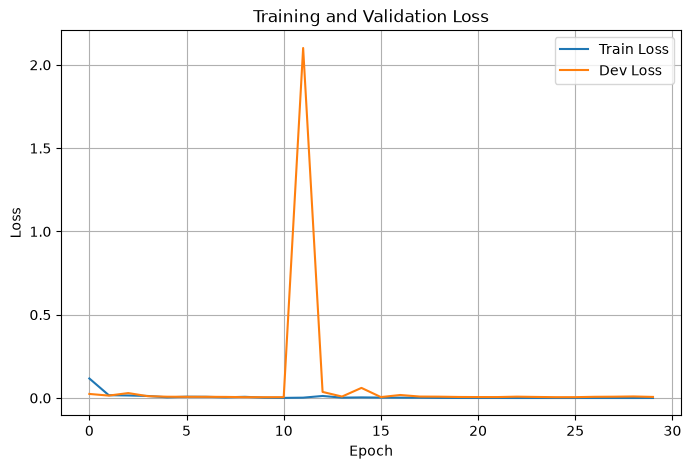

In [17]:
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(8, 5))
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["dev_loss"], label="Dev Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()


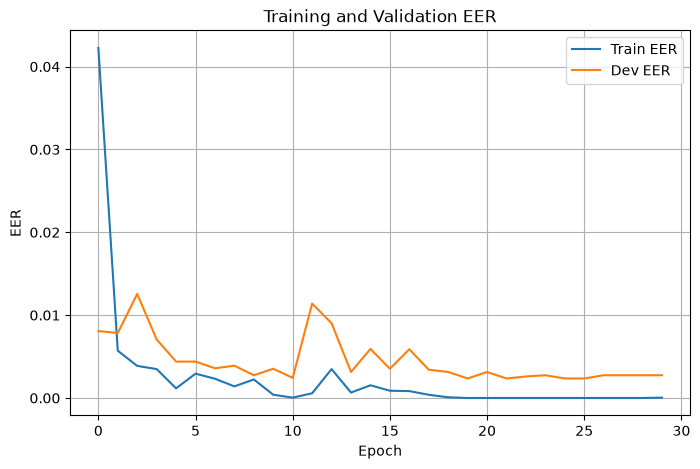

In [18]:
plt.figure(figsize=(8, 5))
plt.plot(history["train_eer"], label="Train EER")
plt.plot(history["dev_eer"], label="Dev EER")
plt.xlabel("Epoch")
plt.ylabel("EER")
plt.title("Training and Validation EER")
plt.legend()
plt.grid()
plt.show()


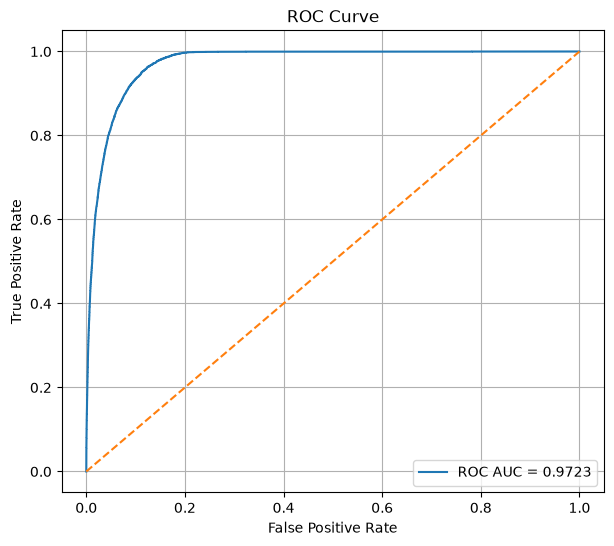

In [19]:
plt.figure(figsize=(7, 6))
plt.plot(
    fpr,
    tpr,
    label=f"ROC AUC = {roc_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid()
plt.show()